# Exploratory A: VAR(p) mean with more lags

*Exploratory notebook, not part of the roadmap.*

**Question.** Do extra daily lags (p = 5 and p = 20) raise the simulated 250-day variance ratio and improve horizon coverage? The daily factor autocorrelations are tiny (about 0.03 at lag 1, noise beyond), so any effect has to come from many small lags adding up.

Only the mean dynamics change: shocks are var1's constant-sigma Student-t (fitted on each model's residuals), so differences from var1 are due to the mean. Same checks as `garch/03_validation.ipynb`: variance ratio, Design A, Design B.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from scenario_lab.data import load_curve
from scenario_lab.models import var1 as m
from scenario_lab import validation as v
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"

levels = load_curve("AAA")
changes = levels.diff().dropna()
realised = v.realised_changes(levels)
FIT_END = v.FIT_END
mats = list(levels.columns)

def shock_params(resid):
    """Constant-sigma Student-t shocks as in var1: per-factor std and df (floored at m.MIN_DF)."""
    sigma = resid.std(axis=0)
    df = np.maximum([stats.t.fit(resid[:, j] / sigma[j], floc=0)[0] for j in range(resid.shape[1])], m.MIN_DF)
    return sigma, np.array(df)

def draw_eps(sigma, df, n_paths, n_days, rng):
    k = len(sigma)
    return sigma * np.sqrt((df - 2) / df) * stats.t.rvs(df, size=(n_paths, n_days, k), random_state=rng)

def curves_from_scores(S, V, y0):
    """S: (n_paths, n_days, k) factor changes -> curves (n_paths, n_days + 1, n_mats)."""
    dy = S @ V.T
    y0 = np.asarray(y0)
    return np.concatenate([np.broadcast_to(y0, (S.shape[0], 1, y0.size)), y0 + np.cumsum(dy, axis=1)], axis=1)

## Model definitions

In [2]:
def fit_varp(changes, p=5, k=3):
    """VAR(p) without intercept on the PCA scores, OLS. Returns dict with V, B (k*p, k), sigma, df."""
    base = m.fit(changes, k)
    s = changes.values @ base.V
    X = np.hstack([s[p - l - 1: len(s) - l - 1] for l in range(p)])      # [s_{t-1}, ..., s_{t-p}]
    Y = s[p:]
    B = np.linalg.lstsq(X, Y, rcond=None)[0]
    sigma, df = shock_params(Y - X @ B)
    return dict(V=base.V, B=B, p=p, sigma=sigma, df=df)

def simulate_varp(q, y0, n_paths=m.N_PATHS, n_days=m.N_DAYS, seed=0):
    rng = np.random.default_rng(seed)
    k = q["V"].shape[1]; p = q["p"]
    eps = draw_eps(q["sigma"], q["df"], n_paths, n_days, rng)
    hist = np.zeros((n_paths, p, k))                    # hist[:, l] = s_{t-1-l}
    S = np.empty((n_paths, n_days, k))
    for t in range(n_days):
        s_t = hist.reshape(n_paths, p * k) @ q["B"] + eps[:, t]
        S[:, t] = s_t
        hist = np.concatenate([s_t[:, None], hist[:, :-1]], axis=1)
    return curves_from_scores(S, q["V"], y0)

In [3]:
models = {"var1": (m.fit, m.simulate),
          "VAR(5)": (lambda ch: fit_varp(ch, 5), simulate_varp),
          "VAR(20)": (lambda ch: fit_varp(ch, 20), simulate_varp)}
q5 = fit_varp(changes, 5)
print("VAR(5) max abs coefficient:", np.abs(q5["B"]).max().round(3), "| sigma", q5["sigma"].round(4), "df", q5["df"].round(1))

VAR(5) max abs coefficient: 0.137 | sigma [0.0869 0.0376 0.0189] df [4.4 3.3 3. ]


## Variance ratio and horizon std (full-sample fit, from today's curve)

Realised `var(250d) / (250 * var(daily))` is 5.7 (1Y), 2.5 (2Y), 1.4 (5Y), 1.2 (10Y), 1.1 (20Y), 0.9 (30Y); var1 gives about 1.1 throughout. A mean model that closes the horizon gap has to move the simulated ratio towards these values.

In [4]:
y0 = levels.iloc[-1].values
fitted = {k: fit(changes) for k, (fit, sim) in models.items()}
curves = {k: models[k][1](fitted[k], y0, seed=0) for k in models}

vr_real = realised.var() / (250 * changes.var())
vr = pd.DataFrame({"realised": vr_real, **{k: pd.Series((c[:, -1] - y0).var(0) / (250 * np.diff(c, axis=1).reshape(-1, 6).var(0)), index=mats)
                                          for k, c in curves.items()}})
print("variance ratio var(250d) / (250 * var(daily))")
print(vr.round(2))
print("\nstd of the 250-day change (pp)")
print(pd.DataFrame({"realised 250d": realised.std().values, **{k: (c[:, -1] - y0).std(0) for k, c in curves.items()}}, index=mats).round(3))

variance ratio var(250d) / (250 * var(daily))
     realised  var1  VAR(5)  VAR(20)
1Y       5.68  1.14    1.46     2.12
2Y       2.45  1.11    1.34     1.76
5Y       1.39  1.04    1.12     1.16
10Y      1.20  1.04    1.06     0.98
20Y      1.07  1.09    1.07     0.97
30Y      0.88  1.10    1.07     0.92

std of the 250-day change (pp)
     realised 250d   var1  VAR(5)  VAR(20)
1Y           1.056  0.459   0.520    0.628
2Y           0.935  0.623   0.685    0.787
5Y           0.763  0.653   0.678    0.690
10Y          0.711  0.658   0.663    0.639
20Y          0.707  0.707   0.701    0.664
30Y          0.696  0.775   0.762    0.706


## Design A: single cut (end-2018)

In [5]:
y0_a = levels.loc[:FIT_END].iloc[-1].values
sims_a = {}
for k, (fit, sim) in models.items():
    c = sim(fit(changes.loc[:FIT_END]), y0_a, seed=0)
    sims_a[k] = c[:, -1] - c[:, 0]
test = realised.loc[FIT_END:]
for band, (lo, hi), nom in [("5-95%", (0.05, 0.95), 0.9), ("25-75%", (0.25, 0.75), 0.5)]:
    print(f"coverage {band} on test windows (nominal {nom:.0%})")
    print(pd.DataFrame({k: v.coverage(s, test, lo, hi) for k, s in sims_a.items()}).round(3), "\n")

coverage 5-95% on test windows (nominal 90%)
      var1  VAR(5)  VAR(20)
1Y   0.563   0.564    0.698
2Y   0.708   0.708    0.822
5Y   0.789   0.789    0.802
10Y  0.811   0.809    0.808
20Y  0.840   0.837    0.832
30Y  0.885   0.879    0.849 

coverage 25-75% on test windows (nominal 50%)
      var1  VAR(5)  VAR(20)
1Y   0.397   0.400    0.454
2Y   0.494   0.494    0.528
5Y   0.573   0.570    0.599
10Y  0.544   0.545    0.528
20Y  0.536   0.524    0.495
30Y  0.580   0.561    0.502 



## Design B: expanding window (origins 2012-2022)

In [6]:
origins = [f"{y}-12-31" for y in range(2012, 2023)]
c90 = {k: {} for k in models}; c50 = {k: {} for k in models}
for o in origins:
    ch_o, y0_o = changes.loc[:o], levels.loc[:o].iloc[-1].values
    test_o = realised[realised.index > o].iloc[:250]
    for k, (fit, sim) in models.items():
        cv = sim(fit(ch_o), y0_o)
        s = cv[:, -1] - cv[:, 0]
        c90[k][o] = v.coverage(s, test_o, 0.05, 0.95); c50[k][o] = v.coverage(s, test_o, 0.25, 0.75)
t90 = {k: pd.DataFrame(v).T for k, v in c90.items()}
t50 = {k: pd.DataFrame(v).T for k, v in c50.items()}
print("pooled 5-95% coverage by maturity (nominal 0.90)")
print(pd.DataFrame({k: t.mean() for k, t in t90.items()}).T.round(3))
print("\nmean |coverage - nominal|, all origins and maturities")
print(pd.DataFrame({"5-95%": {k: (t90[k] - 0.9).abs().values.mean() for k in t90},
                    "25-75%": {k: (t50[k] - 0.5).abs().values.mean() for k in t50}}).round(3))

pooled 5-95% coverage by maturity (nominal 0.90)
            1Y     2Y     5Y    10Y    20Y    30Y
var1     0.831  0.853  0.870  0.822  0.842  0.896
VAR(5)   0.833  0.861  0.869  0.821  0.830  0.885
VAR(20)  0.866  0.880  0.874  0.805  0.798  0.851

mean |coverage - nominal|, all origins and maturities
         5-95%  25-75%
var1     0.185   0.321
VAR(5)   0.186   0.320
VAR(20)  0.185   0.339


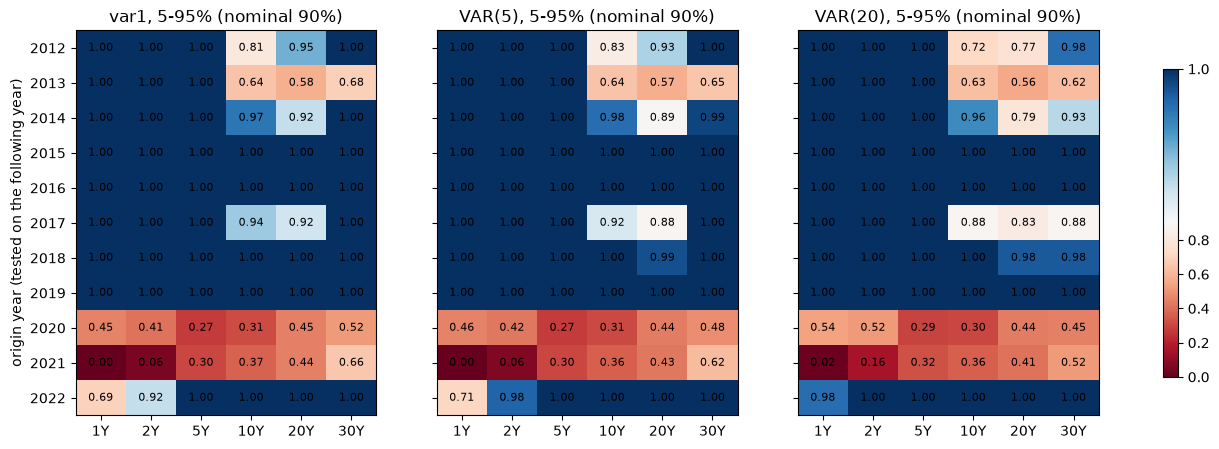

In [7]:
def heat(ax, tab, nominal, title):
    im = ax.imshow(tab.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=nominal, vmin=0, vmax=1), aspect="auto")
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels([o[:4] for o in tab.index])
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); return im

fig, axes = plt.subplots(1, len(t90), figsize=(5.5 * len(t90), 5), sharey=True)
for ax, (k, t) in zip(np.atleast_1d(axes), t90.items()):
    im = heat(ax, t, 0.9, f"{k}, 5-95% (nominal 90%)")
np.atleast_1d(axes)[0].set_ylabel("origin year (tested on the following year)")
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

## Results

- **Variance ratio.** VAR(20) lifts the 1Y ratio from 1.14 to 2.12 and the 2Y ratio from 1.11 to 1.76, still well below the realised 5.7 and 2.5. VAR(5) moves it only to 1.46 and 1.34.
- **Design A.** VAR(20) raises 5-95% test coverage at 1Y (0.56 to 0.70) and 2Y (0.71 to 0.82) but lowers it at 20Y-30Y (0.89 to 0.85 at 30Y), where its variance ratio falls below 1.
- **Design B.** Mean |coverage - nominal| is unchanged for the 5-95% band (0.185 for var1 and for VAR(20)) and worse for the 25-75% band (0.321 to 0.339). Gains at 1Y-2Y are offset by losses at 10Y-30Y.

**Conclusion.** Longer lags help the short end, but one set of lag coefficients on all factors trades short-end for long-end accuracy, with no net gain in coverage. VAR(20) has 180 coefficients on about 22 years of data, so read these results as indicative.